# Analysis Human-Team (pair B): Q2

### Load and Import

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch
from tqdm.auto import tqdm

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------
from pair_b.q2_helpers import (relation_features, image_stats, ego_share, seq_share,
                               gallery, model_view)

print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()

# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")

c:\Users\maxha\Documents\JKU\WS26\AI_visualisation_UE\ai_and_visualisation_OpenSI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.11.0+cu128 | CUDA build 12.8
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}, {subregion}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP


In [2]:
# Q2 uses the paper prompt, independent of the default in shared/
cfg.prompt_template = "A Street View photo in {country}."
print("main run prompt:", info["prompt_template"])

main run prompt: A Street View photo in {country}.


## Q2: Overconfidence and training coverage

> When is the model confidently wrong and what do those images share: scene type, misleading clues, or image quality (dashcam, blur, night)? Can we infer from this behaviour which countries were in StreetCLIP's training and does that match the published list (e.g. India and China)? Is there a hard cut in countries the model is better at?

- **Confidence** = probability of the top-1 country
- **Confident error** = wrong prediction with confidence > 0.8
- **Calibrated** = when the model says 80 %, it is right 80 % of the time

In [3]:
THRESHOLD = 0.8
attrs = mapper.table

df = preds[preds["representable"]].copy()       # only countries that are candidates
df["correct"] = df["correct"].astype(bool)
df["confidence"] = df["prob_1"]
df["in_list"] = df["country_id"].map(attrs["in_paper_training_list"]).fillna(0).astype(int) == 1

groups = []
for conf, corr in zip(df["confidence"], df["correct"]):
    if conf > THRESHOLD and corr:
        groups.append("confident correct")
    elif conf > THRESHOLD:
        groups.append("confident error")
    elif corr:
        groups.append("unsure correct")
    else:
        groups.append("unsure error")
df["group"] = groups

print(df["group"].value_counts())

group
unsure error         97268
unsure correct       60117
confident correct    45672
confident error       5257
Name: count, dtype: int64


### F1: Is the model calibrated?
We compare countries in the paper's training list with countries that are not in it.

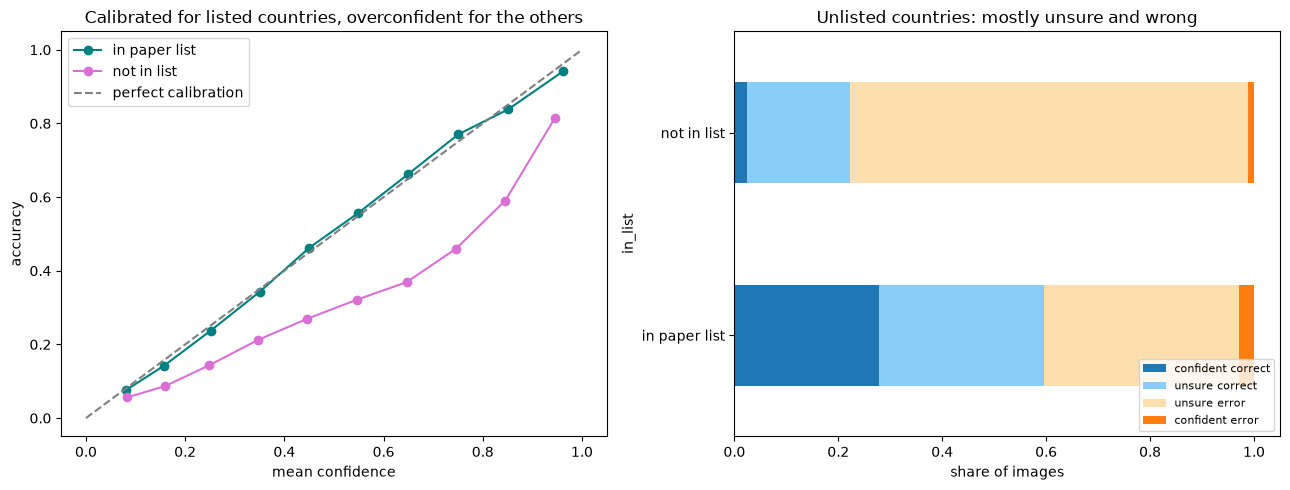

in_list,in paper list,not in list
group,,
confident correct,0.279,0.025
unsure correct,0.316,0.198
unsure error,0.376,0.766
confident error,0.029,0.012


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for in_list, label, color in [(True, "in paper list", "teal"), (False, "not in list", "orchid")]:
    part = df[df["in_list"] == in_list]
    bins = pd.cut(part["confidence"], np.linspace(0, 1, 11))
    stats = part.groupby(bins, observed=True).agg(conf=("confidence", "mean"), acc=("correct", "mean"))
    axes[0].plot(stats["conf"], stats["acc"], marker="o", color=color, label=label)
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
axes[0].set_xlabel("mean confidence")
axes[0].set_ylabel("accuracy")
axes[0].set_title("Calibrated for listed countries, overconfident for the others")
axes[0].legend()

order = ["confident correct", "unsure correct", "unsure error", "confident error"]
shares = pd.crosstab(df["group"], df["in_list"].map({True: "in paper list", False: "not in list"}),
                     normalize="columns").reindex(order)
shares.T.plot(kind="barh", stacked=True, ax=axes[1],
              color=["tab:blue", "lightskyblue", "navajowhite", "tab:orange"])
axes[1].set_xlabel("share of images")
axes[1].set_title("Unlisted countries: mostly unsure and wrong")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

display(shares.round(3))

**F1:** For countries in the paper's list the curve sits almost exactly on the diagonal: when the model says 90 %, it's right about 90 % of the time. For the other countries it's clearly below, so the model is less sure there, but still not unsure enough. Most of their images end up as unsure errors (77 %), only 2.5 % are confident and correct (listed: 28 %). Surprisingly, confident errors are more common in listed countries (2.9 % vs 1.2 %). So what do these confident errors have in common?

### F2: What do the confident errors have in common?
We compare all confident errors with the same number of confident correct images **from the same countries** (otherwise the US-heavy errors would differ just because of the country). A feature only matters if it is clearly more common among the errors.

In [5]:
errors = df[df["group"] == "confident error"]
correct = df[df["group"] == "confident correct"]

parts = []
for country, n in errors["country_id"].value_counts().items():
    pool = correct[correct["country_id"] == country]
    if len(pool) > 0:
        parts.append(pool.sample(min(n, len(pool)), random_state=0))
reference = pd.concat(parts)

work = pd.concat([errors, reference]).reset_index(drop=True)
work["is_error"] = work["group"] == "confident error"
print(f"{len(errors):,} confident errors, {len(reference):,} reference images")

5,257 confident errors, 4,828 reference images


In [6]:
# Feature 1: name clash (the country name also means something else, e.g. the US state Georgia)
# For correct images we look at the model's 2nd guess
NAME_CLASHES = [("US", "GE"), ("US", "MX"), ("GB", "IE"), ("NG", "NE"), ("NE", "NG"),
                ("DO", "DM"), ("DM", "DO"), ("SS", "SD"), ("SD", "SS"), ("KR", "KP"), ("KP", "KR")]
clash = []
for true_c, p1, p2, is_err in zip(work["country_id"], work["pred_1"], work["pred_2"], work["is_error"]):
    other = p1 if is_err else p2
    clash.append((true_c, other) in NAME_CLASHES)
work["name_clash"] = clash

# Feature 2 + 3: brightness / contrast, and rotated (sky at the bottom)
# Feature 4: hood / dashboard visible (segmentation class "Ego Vehicle", cached from earlier runs)
segmenter = Segmenter(cfg)
ego_ids = []
for class_id, name in segmenter.model.config.id2label.items():
    if "ego" in name.lower():
        ego_ids.append(int(class_id))

brightness, contrast, top_minus_bottom, ego = [], [], [], []
for image_id in tqdm(work["id"], desc="image features"):
    img = fit_image(dataset.get_image(image_id), cfg.crop_mode)      # what the model sees
    gray = np.asarray(img).astype(float).mean(axis=2)
    third = gray.shape[0] // 3
    brightness.append(gray.mean())
    contrast.append(gray.std())
    top_minus_bottom.append(gray[:third].mean() - gray[-third:].mean())
    labels = segmenter.label_map(img, image_id=f"q2crop_{image_id}")
    ego.append(np.isin(labels, ego_ids).mean())

work["brightness"] = brightness
work["contrast"] = contrast
work["rotated"] = np.array(top_minus_bottom) < -40
work["hood"] = (np.array(ego) > 0.03) & ~work["rotated"]       # rotated images look like "ego vehicle"

del segmenter
free_gpu_memory()

W1107 21:12:51.397000 18316 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 758/758 [00:00<00:00, 1060.21it/s]
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-mapillary-vistas-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.bias                            

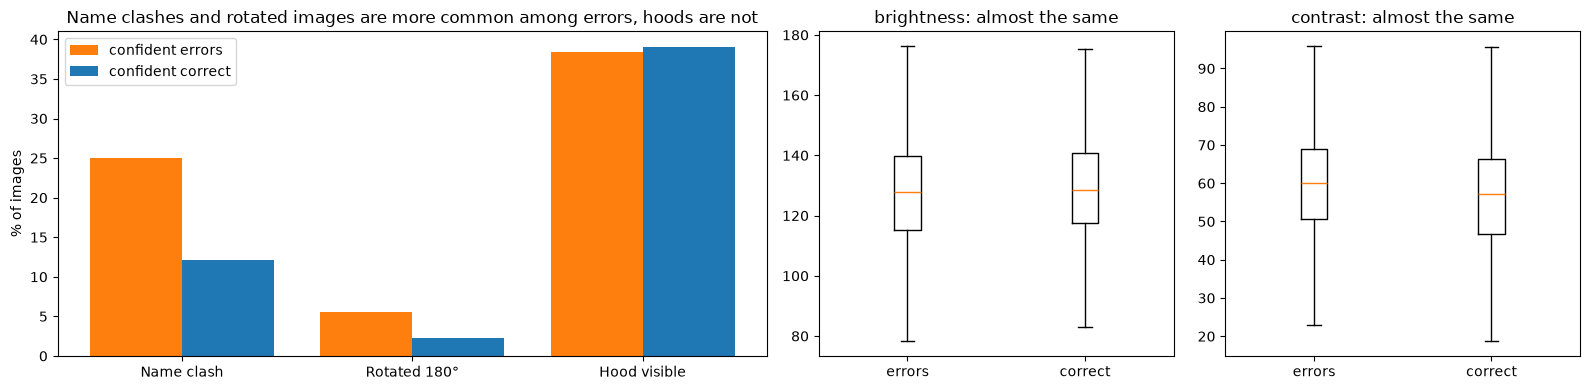

Name clash     errors 25.0%   correct 12.1%
Rotated 180°   errors 5.5%   correct 2.2%
Hood visible   errors 38.4%   correct 39.1%
name clash without US: errors 4.2%   correct 5.1%


is_error,correct,errors
land_cover_name,,
artificial surfaces,11.2,6.7
bare soil,1.6,3.4
cropland,40.1,27.2
grassland,14.5,10.2
"herbaceous, flooded",1.2,2.9
mangroves,0.0,0.0
no data,0.0,0.1
shrubs,8.9,9.7
snow and glaciers,0.0,0.0


In [7]:
features = {"name_clash": "Name clash", "rotated": "Rotated 180°", "hood": "Hood visible"}

err_share, ref_share = [], []
for col in features:
    err_share.append(work.loc[work["is_error"], col].mean() * 100)
    ref_share.append(work.loc[~work["is_error"], col].mean() * 100)

x = np.arange(len(features))
fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={"width_ratios": [2, 1, 1]})
axes[0].bar(x - 0.2, err_share, 0.4, color="tab:orange", label="confident errors")
axes[0].bar(x + 0.2, ref_share, 0.4, color="tab:blue", label="confident correct")
axes[0].set_xticks(x, features.values())
axes[0].set_ylabel("% of images")
axes[0].set_title("Name clashes and rotated images are more common among errors, hoods are not")
axes[0].legend()

for ax, col in zip(axes[1:], ["brightness", "contrast"]):
    ax.boxplot([work.loc[work["is_error"], col], work.loc[~work["is_error"], col]],
               tick_labels=["errors", "correct"], showfliers=False)
    ax.set_title(f"{col}: almost the same")
plt.tight_layout()
plt.show()

for col, label in features.items():
    print(f"{label:14s} errors {work.loc[work['is_error'], col].mean():.1%}   "
          f"correct {work.loc[~work['is_error'], col].mean():.1%}")
no_us = work[work["country_id"] != "US"]
print(f"name clash without US: errors {no_us.loc[no_us['is_error'], 'name_clash'].mean():.1%}   "
      f"correct {no_us.loc[~no_us['is_error'], 'name_clash'].mean():.1%}")

# Scene type: land cover
lc = pd.crosstab(work["land_cover_name"], work["is_error"].map({True: "errors", False: "correct"}),
                 normalize="columns")
display((lc * 100).round(1))

### Drill-down: the Georgia case
"Georgia" is a country and a US state. Which US states are called "Georgia", and what happens if we make the prompt unambiguous?

2,345 US images predicted as Georgia, they come from:


region
Georgia           401
North Carolina    347
South Carolina    271
Alabama           243
Mississippi       211
Arkansas          145
Name: count, dtype: int64

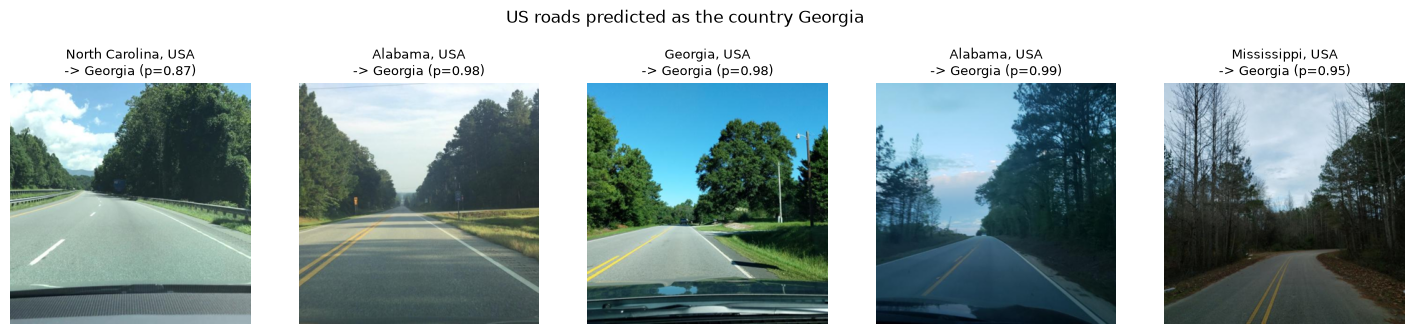

,prompt,US -> Georgia,US accuracy,real Georgia accuracy
0,paper prompt,2345,0.628,0.000
1,Georgia prompt clarified,9,0.723,0.231


In [8]:
us_ge = df[(df["country_id"] == "US") & (df["pred_1"] == "GE")]
print(f"{len(us_ge):,} US images predicted as Georgia, they come from:")
display(dataset.meta.loc[us_ge["id"], "region"].value_counts().head(6))

sample = us_ge[us_ge["confidence"] > THRESHOLD].sample(5, random_state=0)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (_, r) in zip(axes, sample.iterrows()):
    ax.imshow(fit_image(dataset.get_image(r["id"]), cfg.crop_mode))
    region = dataset.meta.loc[r["id"], "region"]
    ax.set_title(f"{region}, USA\n-> Georgia (p={r['confidence']:.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle("US roads predicted as the country Georgia")
plt.show()

# Test: same images, only the Georgia prompt changed ("Georgia, the country in the Caucasus")
fix, _, _, _ = PredictionRunner.load(f"results/shared/{run_name}_gefix")
fix = fix[fix["representable"]].copy()
fix["correct"] = fix["correct"].astype(bool)

rows = []
for label, table in [("paper prompt", df), ("Georgia prompt clarified", fix)]:
    us = table[table["country_id"] == "US"]
    ge = table[table["country_id"] == "GE"]
    rows.append({"prompt": label,
                 "US -> Georgia": int((us["pred_1"] == "GE").sum()),
                 "US accuracy": round(us["correct"].mean(), 3),
                 "real Georgia accuracy": round(ge["correct"].mean(), 3)})
display(pd.DataFrame(rows))

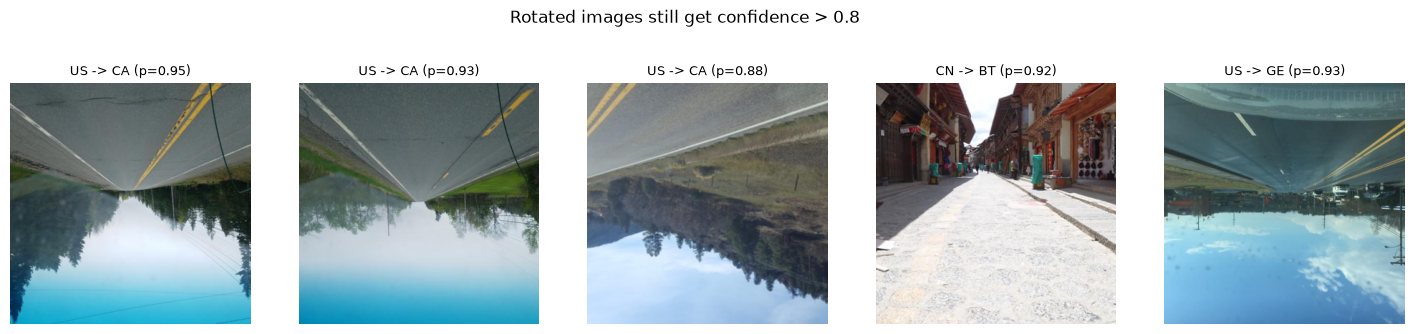

In [9]:
rot = work[work["is_error"] & work["rotated"]].sample(5, random_state=0)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (_, r) in zip(axes, rot.iterrows()):
    ax.imshow(fit_image(dataset.get_image(r["id"]), cfg.crop_mode))
    ax.set_title(f"{r['country_id']} -> {r['pred_1']} (p={r['confidence']:.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle("Rotated images still get confidence > 0.8")
plt.show()

**F2:** The biggest cause isn't in the image at all: 25 % of the confident errors are name clashes, compared to 12 % of the reference. Without the US it's 4 % vs 5 %, so it's basically one case: US -> Georgia. 2,345 US images are called "Georgia", and they come from the whole US Southeast (Georgia, North and South Carolina, Alabama, Mississippi, ...). When we change only the Georgia prompt to "Georgia, the country in the Caucasus", this drops to 9 images, US accuracy goes from 63 % to 72 %, and real Georgia images are recognised for the first time (0 % -> 23 %). So the error comes from the ambiguous word in the prompt, not from the images.

Rotated images are the second cause (5.5 % vs 2.2 %): clearly broken inputs, but the model is still very sure.

Things that don't explain the errors: the hood/dashboard view (38 % vs 39 %), brightness and contrast (almost the same). Errors are more often on tree-covered roads (33 % vs 19 %) and less often in cropland (27 % vs 40 %), but that fits the forest roads of the Georgia case, so it's probably the same effect. Night images can't be tested because OSV-5M already removed them, and we didn't measure blur.

### F3: Can we see which countries were in training?
If a country was in StreetCLIP's training, it should (1) be predicted better and (2) gain more compared to the original CLIP. Is there a hard cut?

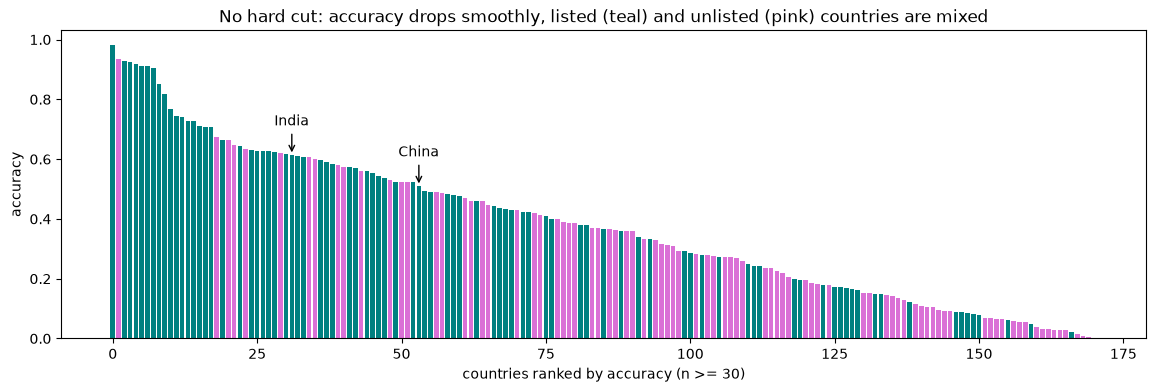

In [10]:
per_country = df.groupby("country_id").agg(n=("correct", "size"), accuracy=("correct", "mean"))
per_country = per_country[per_country["n"] >= 30].sort_values("accuracy", ascending=False)
per_country["in_list"] = per_country.index.map(attrs["in_paper_training_list"]).fillna(0).astype(int) == 1

colors = []
for in_list in per_country["in_list"]:
    if in_list:
        colors.append("teal")
    else:
        colors.append("orchid")

plt.figure(figsize=(14, 4))
plt.bar(range(len(per_country)), per_country["accuracy"], color=colors)
for c in ["IN", "CN"]:
    pos = list(per_country.index).index(c)
    plt.annotate(attrs.loc[c, "prompt_name"], (pos, per_country.loc[c, "accuracy"]),
                 xytext=(pos, per_country.loc[c, "accuracy"] + 0.1), ha="center",
                 arrowprops=dict(arrowstyle="->"))
plt.xlabel("countries ranked by accuracy (n >= 30)")
plt.ylabel("accuracy")
plt.title("No hard cut: accuracy drops smoothly, listed (teal) and unlisted (pink) countries are mixed")
plt.show()

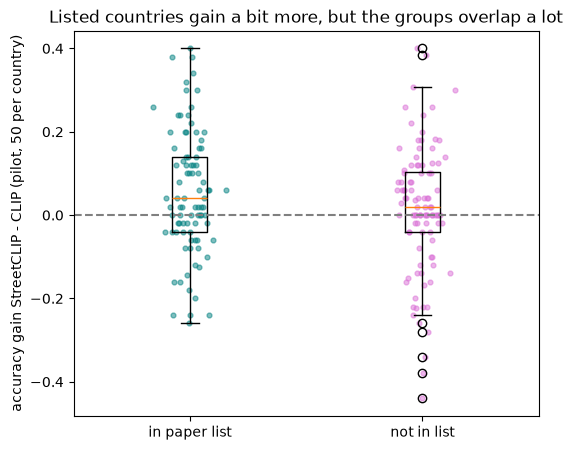

in_list
False    0.02
True     0.04
Name: gain, dtype: float64


,streetclip,clip,gain,in_list
country_id,,,,
IN,0.64,0.50,0.14,True
CN,0.54,0.34,0.20,True


In [11]:
clip_dir = Path(f"results/pair_b/clip_pilot_{cfg.candidate_list}_{cfg.crop_mode}")
if not clip_dir.exists():      # ~4 min the first time
    clip = GeoCLIPModel(cfg.clip_model, cfg)
    cands = mapper.candidates(cfg.candidate_list)
    clip.set_candidates(cands, mapper.prompts(cands, cfg.prompt_template))
    PredictionRunner(cfg, dataset, mapper).run(clip, pilot_ids, run_name=clip_dir.name, out_dir=clip_dir)
    del clip
    free_gpu_memory()
clip_preds, _, _, _ = PredictionRunner.load(clip_dir)

def pilot_accuracy(table):
    t = table[table["representable"]].copy()
    t["correct"] = t["correct"].astype(bool)
    return t.groupby("country_id")["correct"].mean()

gain = pd.DataFrame({"streetclip": pilot_accuracy(preds[preds["id"].isin(set(pilot_ids))]),
                     "clip": pilot_accuracy(clip_preds)}).dropna()
gain["gain"] = gain["streetclip"] - gain["clip"]
gain["in_list"] = gain.index.map(attrs["in_paper_training_list"]).fillna(0).astype(int) == 1

listed = gain[gain["in_list"]]["gain"]
unlisted = gain[~gain["in_list"]]["gain"]
plt.figure(figsize=(6, 5))
plt.boxplot([listed, unlisted], tick_labels=["in paper list", "not in list"])
plt.scatter(np.random.normal(1, 0.05, len(listed)), listed, s=12, alpha=0.5, color="teal")
plt.scatter(np.random.normal(2, 0.05, len(unlisted)), unlisted, s=12, alpha=0.5, color="orchid")
plt.axhline(0, color="gray", linestyle="--")
plt.ylabel("accuracy gain StreetCLIP - CLIP (pilot, 50 per country)")
plt.title("Listed countries gain a bit more, but the groups overlap a lot")
plt.show()

print(gain.groupby("in_list")["gain"].median().round(3))
display(gain.loc[["IN", "CN"]].round(2))

**F3:** There's no hard cut: ranked by accuracy, the countries drop smoothly, and listed and unlisted countries are mixed along the whole ranking (only the top ~20 are almost all listed). Compared to the original CLIP, listed countries gain a bit more from fine-tuning (median +4 vs +2 points), but the two groups overlap a lot, and with 50 pilot images per country the gains are noisy. India goes from 50 % to 64 % and China from 34 % to 54 %, so both improve through fine-tuning, which fits the paper's list (where both are included) more than the model card (which says they were excluded). The clearest sign that the list is roughly right is still the calibration difference from F1.

## Answer to Q2

- **When is it confidently wrong?** Mostly when a country name is ambiguous: US images from the Southeast get called "Georgia", because the word also means the US state. Clarifying the prompt removes almost all of these errors. Rotated images are the second cause. The hood view, brightness/contrast and scene type don't explain the errors.
- **Training coverage:** confidence is reliable for the countries in the paper's list and too high for the others. But there's no hard cut in accuracy, and the gain over CLIP only shows a weak tendency. India and China both improve through fine-tuning, which fits the paper's list rather than the model card.
- **Limitations:** the 0.8 threshold is our choice; the rotation flag is a simple brightness rule; blur wasn't measured; 50 pilot images per country make the CLIP gain noisy.

# Analysis Human-Team (pair B): Q3

Maximmilian

### Load and Import

In [ ]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch
from tqdm.auto import tqdm

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------
from pair_b.q2_helpers import (relation_features, image_stats, ego_share, seq_share,
                               gallery, model_view)

print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()

# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")

c:\Users\maxha\Documents\JKU\WS26\AI_visualisation_UE\ai_and_visualisation_OpenSI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.11.0+cu128 | CUDA build 12.8
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}, {subregion}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP


In [ ]:
# Q3 uses the paper prompt, independent of the default in shared/
cfg.prompt_template = "A Street View photo in {country}."
print("main run prompt:", info["prompt_template"], "| Q3 prompt:", cfg.prompt_template)

main run prompt: A Street View photo in {country}. | Q3 prompt: A Street View photo in {country}.


## Q3: Visual clues

> Which elements (text, road, vegetation, sky, ...) change the prediction when hidden, and does this differ between countries?

For each image we hide one element at a time (gray fill) and run StreetCLIP again. As a control we also hide random areas of the same size, because hiding *any* part of the image changes something. An element only counts as a clue if hiding it changes more than hiding a random area of the same size.

In [ ]:
Q3_PER_COUNTRY = 20

pilot = preds[preds["id"].isin(set(pilot_ids)) & preds["representable"]].copy()

parts = []
for country, group in pilot.groupby("country_id"):
    parts.append(group.sample(min(Q3_PER_COUNTRY, len(group)), random_state=0))
q3_sample = pd.concat(parts)
q3_ids = q3_sample["id"].tolist()

print(f"{len(q3_ids):,} images from {q3_sample['country_id'].nunique()} countries")

3,660 images from 188 countries


In [ ]:
# Segmentation + text detection for all sample images (cached in data/masks/)
segmenter = Segmenter(cfg)
text_detector = TextDetector(cfg)
print("unknown class names:", segmenter.unmatched)

for image_id in tqdm(q3_ids, desc="segmentation + text"):
    img = dataset.get_image(image_id)
    segmenter.element_masks(img, image_id=image_id)
    text_detector.text_mask(img, image_id=image_id)

W1107 15:38:32.851000 32980 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 758/758 [00:00<00:00, 1041.06it/s]
[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-mapillary-vistas-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                          

unknown class names: []


segmentation + text: 100%|██████████| 3660/3660 [00:26<00:00, 135.97it/s]


### How the masking works
The segmentation splits the image into elements. One element is hidden with a gray block (CLIP's mean colour, i.e. "no information" for the model), and the same shape is also hidden at random other positions as a control.

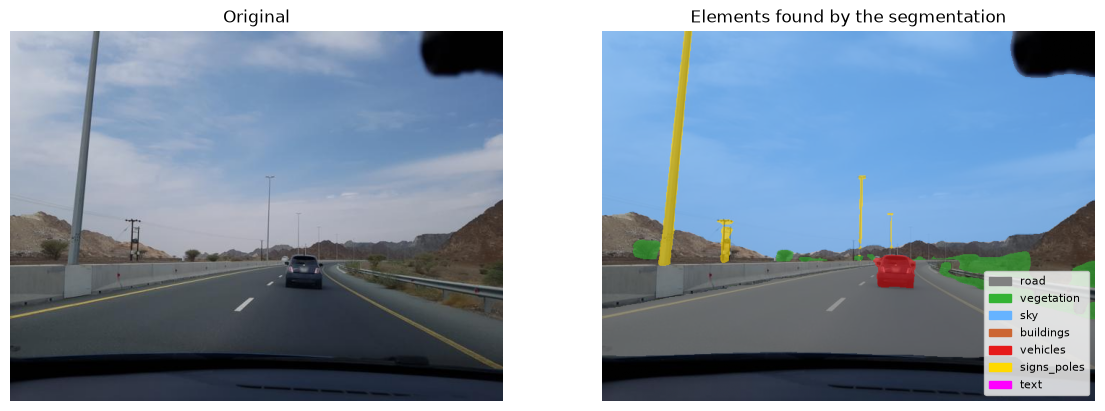

In [ ]:
applier = MaskApplier(cfg)
EXAMPLE_ID = q3_ids[0]              # or any image id
img = dataset.get_image(EXAMPLE_ID)
masks = segmenter.element_masks(img, image_id=EXAMPLE_ID)
masks["text"] = text_detector.text_mask(img, image_id=EXAMPLE_ID)

colors = {"road": (0.5, 0.5, 0.5), "vegetation": (0.2, 0.7, 0.2), "sky": (0.4, 0.7, 1.0),
          "buildings": (0.8, 0.4, 0.2), "vehicles": (0.9, 0.1, 0.1), "signs_poles": (1.0, 0.85, 0.0),
          "text": (1.0, 0.0, 1.0)}
overlay = np.asarray(img).astype(float) / 255
for element, mask in masks.items():
    overlay[mask] = 0.4 * overlay[mask] + 0.6 * np.array(colors[element])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(img)
axes[0].set_title("Original")
axes[1].imshow(overlay)
axes[1].set_title("Elements found by the segmentation")
for ax in axes:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
axes[1].legend(handles, colors.keys(), loc="lower right", fontsize=8)
plt.show()

element = "road"                    # element used in the next plot
grown = applier.dilate(masks[element])

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 2994.66it/s]


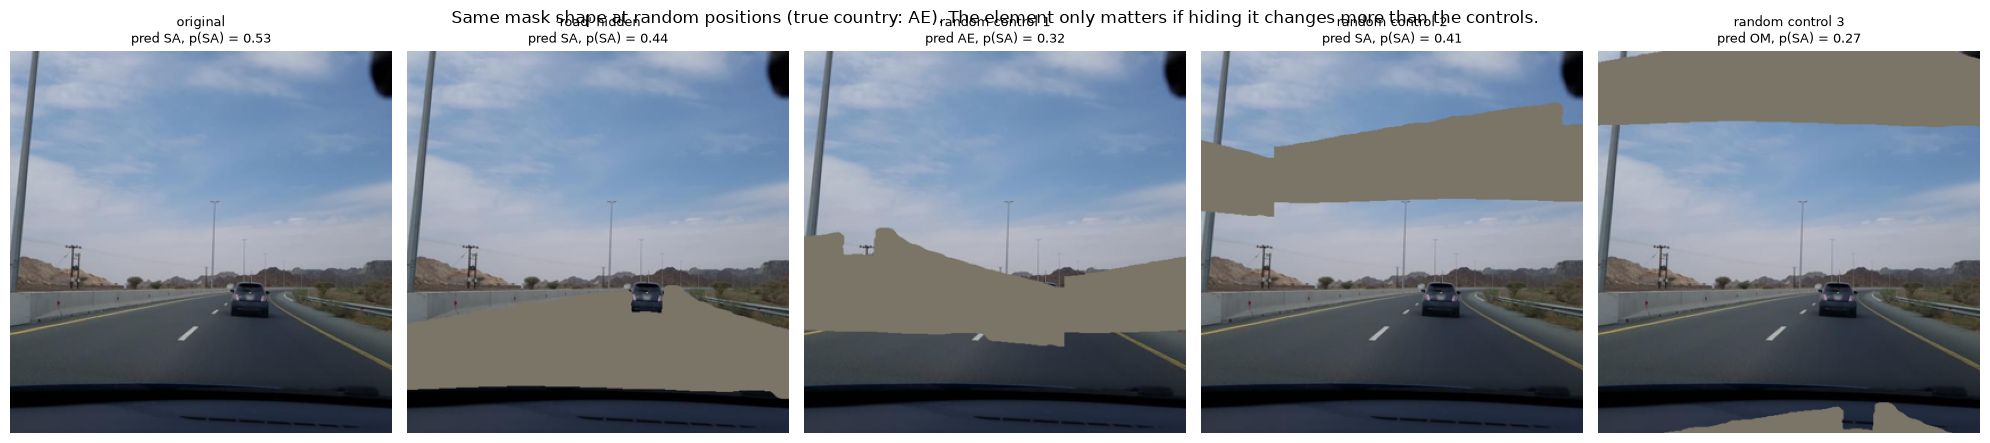

In [ ]:
model = GeoCLIPModel(cfg.streetclip_model, cfg)
candidates = mapper.candidates(cfg.candidate_list)
model.set_candidates(candidates, mapper.prompts(candidates, cfg.prompt_template))

real = applier.fill(img, grown)
controls = applier.apply_controls(img, grown, seed=0)

versions = [img, real]
titles = ["original", f"'{element}' hidden"]
for k, c in enumerate(controls):
    versions.append(c["image"])
    titles.append(f"random control {k + 1}")

probs = model.predict(versions)["probs"]
true_c = dataset.meta.loc[EXAMPLE_ID, "country_id"]
orig_pred = model.labels[probs[0].argmax()]
i_orig = model.labels.index(orig_pred)

fig, axes = plt.subplots(1, len(versions), figsize=(4 * len(versions), 4.5))
for ax, v, t, p in zip(axes, versions, titles, probs):
    ax.imshow(fit_image(v, cfg.crop_mode))
    ax.set_title(f"{t}\npred {model.labels[p.argmax()]}, p({orig_pred}) = {p[i_orig]:.2f}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Same mask shape at random positions (true country: {true_c}). "
             f"The element only matters if hiding it changes more than the controls.")
plt.tight_layout()
plt.show()

### Masking experiment
Every sample image: original + each element hidden + 3 random controls per element. Results go to `results/pair_b/q3_masking.csv` (saved every 100 images; if it stops, just run the cell again).

In [ ]:
out_file = Path("results/pair_b/q3_masking.csv")
label_index = {label: j for j, label in enumerate(model.labels)}

# Resume: skip images that are already in the file
done = set()
if out_file.exists():
    done = set(pd.read_csv(out_file, dtype={"id": str})["id"])
todo = []
for i in q3_ids:
    if i not in done:
        todo.append(i)
print(f"{len(done):,} images already done, {len(todo):,} to go")

rows = []
for n, image_id in enumerate(tqdm(todo, desc="masking")):
    img = dataset.get_image(image_id)
    true_country = q3_sample.loc[q3_sample["id"] == image_id, "country_id"].iloc[0]

    masks = segmenter.element_masks(img, image_id=image_id)
    masks["text"] = text_detector.text_mask(img, image_id=image_id)

    # All versions of this image, then one model call for the whole batch
    images = [img]
    meta = [{"element": "none", "kind": "original", "control": -1, "visible": 0.0}]
    for element, mask in masks.items():
        result = applier.apply(img, mask, element, image_id=image_id)
        if result["image"] is None:          # element missing or too small in the visible part
            continue
        images.append(result["image"])
        meta.append({"element": element, "kind": "element", "control": -1,
                     "visible": result["visible_fraction"]})
        controls = applier.apply_controls(img, result["mask"], seed=n * 100 + len(images))
        for k, c in enumerate(controls):
            images.append(c["image"])
            meta.append({"element": element, "kind": "control", "control": k,
                         "visible": c["visible_fraction"]})

    probs = model.predict(images)["probs"]
    orig_pred = model.labels[probs[0].argmax()]

    for p, m in zip(probs, meta):
        rows.append({"id": image_id, "country_id": true_country, **m,
                     "orig_pred": orig_pred,
                     "new_pred": model.labels[p.argmax()],
                     "p_orig_pred": p[label_index[orig_pred]],
                     "p_true": p[label_index[true_country]],
                     "p_top": p.max()})

    if (n + 1) % 100 == 0 or n + 1 == len(todo):
        pd.DataFrame(rows).to_csv(out_file, mode="a", header=not out_file.exists(), index=False)
        rows = []

del model
free_gpu_memory()
print("skipped masks:", len(applier.skipped))

0 images already done, 3,660 to go


masking: 100%|██████████| 3660/3660 [44:34<00:00,  1.37it/s]  


skipped masks: 11515


## Q3 Analysis

- **Effect** = change of the probability of the true country after hiding (percentage points)
- **Adjusted effect** = effect of the element − average effect of its 3 random controls

An element is a clue if its adjusted effect is clearly below 0, i.e. hiding it hurts more than hiding any area of that size.

In [ ]:
q3 = pd.read_csv("results/pair_b/q3_masking.csv", dtype={"id": str})
orig = q3[q3["kind"] == "original"][["id", "p_true"]].rename(columns={"p_true": "p_true_0"})
q3 = q3.merge(orig, on="id")
q3["correct_0"] = q3["orig_pred"] == q3["country_id"]
q3["d_true"] = (q3["p_true"] - q3["p_true_0"]) * 100
q3["right_to_wrong"] = q3["correct_0"] & (q3["new_pred"] != q3["country_id"])
q3["region"] = q3["country_id"].map(mapper.table["world_region"])

elem = q3[q3["kind"] == "element"]
ctrl = q3[q3["kind"] == "control"].groupby(["id", "element"])[["d_true", "right_to_wrong"]].mean().reset_index()
pairs = elem.merge(ctrl, on=["id", "element"], suffixes=("", "_ctrl"))
pairs["d_true_adj"] = pairs["d_true"] - pairs["d_true_ctrl"]

n_images = q3["id"].nunique()
print(f"{n_images:,} images")
print("share of images where the element could be hidden:")
print((elem.groupby("element")["id"].nunique() / n_images).sort_values(ascending=False).round(2))

3,660 images
share of images where the element could be hidden:
element
sky            0.92
vegetation     0.92
road           0.85
signs_poles    0.63
buildings      0.29
vehicles       0.18
text           0.06
Name: id, dtype: float64


### Q3.1 Which element matters?
Left: change of P(true country) when the element is hidden (orange) vs when the same area is hidden at random (blue). Right: the difference (adjusted effect) with 95 % interval. The table below shows how often a correct prediction turns wrong.

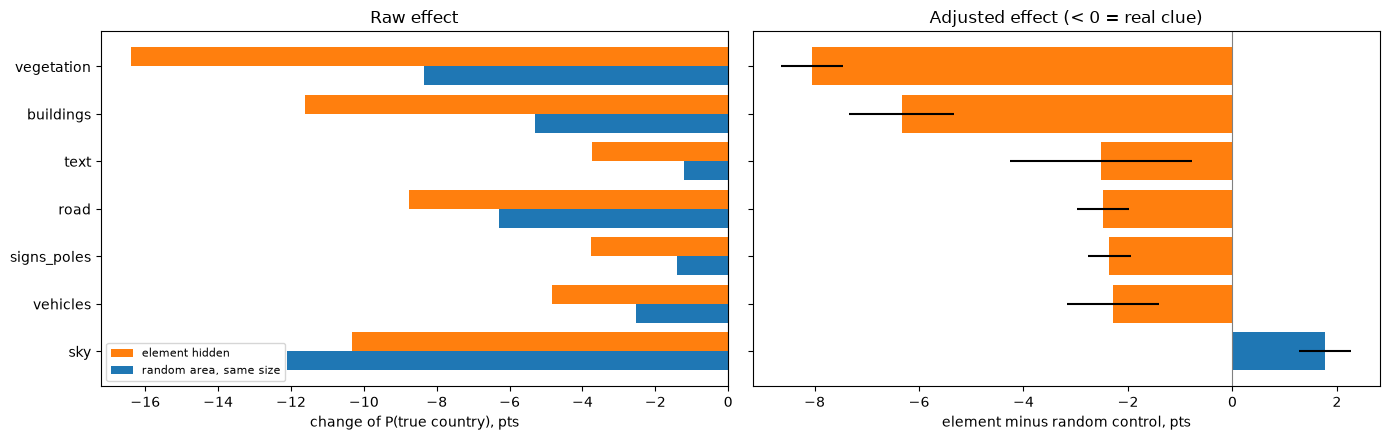

,n,d_elem,d_ctrl,adj,ci
element,,,,,
vegetation,3353,-16.40,-8.35,-8.05,0.59
buildings,1056,-11.63,-5.29,-6.33,1.00
text,220,-3.73,-1.21,-2.51,1.74
road,3119,-8.77,-6.29,-2.48,0.50
signs_poles,2318,-3.76,-1.41,-2.35,0.41
vehicles,658,-4.82,-2.54,-2.29,0.88
sky,3381,-10.32,-12.10,1.78,0.50


,% right->wrong (element),% right->wrong (random)
element,,
vegetation,65.7,39.0
buildings,37.7,22.8
text,16.1,9.5
road,37.1,30.0
signs_poles,19.2,12.1
vehicles,28.9,20.2
sky,43.5,47.8


In [ ]:
summary = pairs.groupby("element").agg(
    n=("id", "size"),
    d_elem=("d_true", "mean"),
    d_ctrl=("d_true_ctrl", "mean"),
    adj=("d_true_adj", "mean"),
    adj_std=("d_true_adj", "std"),
)
summary["ci"] = 1.96 * summary["adj_std"] / np.sqrt(summary["n"])
summary = summary.sort_values("adj")          # strongest clue on top

y = np.arange(len(summary))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

axes[0].barh(y - 0.2, summary["d_elem"], 0.4, color="tab:orange", label="element hidden")
axes[0].barh(y + 0.2, summary["d_ctrl"], 0.4, color="tab:blue", label="random area, same size")
axes[0].axvline(0, color="gray", linewidth=0.8)
axes[0].set_yticks(y, summary.index)
axes[0].invert_yaxis()
axes[0].set_xlabel("change of P(true country), pts")
axes[0].set_title("Raw effect")
axes[0].legend(fontsize=8)

colors = []
for a in summary["adj"]:
    if a < 0:
        colors.append("tab:orange")
    else:
        colors.append("tab:blue")
axes[1].barh(y, summary["adj"], xerr=summary["ci"], color=colors)
axes[1].axvline(0, color="gray", linewidth=0.8)
axes[1].set_xlabel("element minus random control, pts")
axes[1].set_title("Adjusted effect (< 0 = real clue)")
plt.tight_layout()
plt.show()

display(summary[["n", "d_elem", "d_ctrl", "adj", "ci"]].round(2))

r2w = pairs[pairs["correct_0"]].groupby("element")[["right_to_wrong", "right_to_wrong_ctrl"]].mean() * 100
display(r2w.loc[summary.index].round(1).rename(columns={"right_to_wrong": "% right->wrong (element)",
                                                        "right_to_wrong_ctrl": "% right->wrong (random)"}))

### Q3.2 Does it differ between regions?
Adjusted effect per element and world region (only cells with at least 20 images). Red = hiding this element hurts more than a random area.

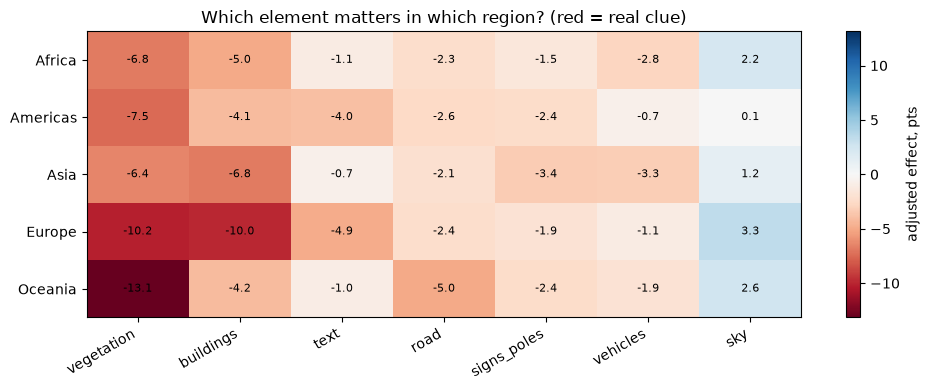

In [ ]:
table = pairs.groupby(["region", "element"]).agg(adj=("d_true_adj", "mean"), n=("id", "size")).reset_index()
table = table[table["n"] >= 20]
heat = table.pivot(index="region", columns="element", values="adj")
order = []
for e in summary.index:
    if e in heat.columns:
        order.append(e)
heat = heat[order]                     # same element order as above

plt.figure(figsize=(10, 4))
limit = np.nanmax(np.abs(heat.values))
plt.imshow(heat.values, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
plt.colorbar(label="adjusted effect, pts")
plt.xticks(range(len(heat.columns)), heat.columns, rotation=30, ha="right")
plt.yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            plt.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8)
plt.title("Which element matters in which region? (red = real clue)")
plt.tight_layout()
plt.show()

### Q3.3 Drill-down: what does it look like?
Images where hiding the strongest clue changes the most (original vs element hidden vs one random control).

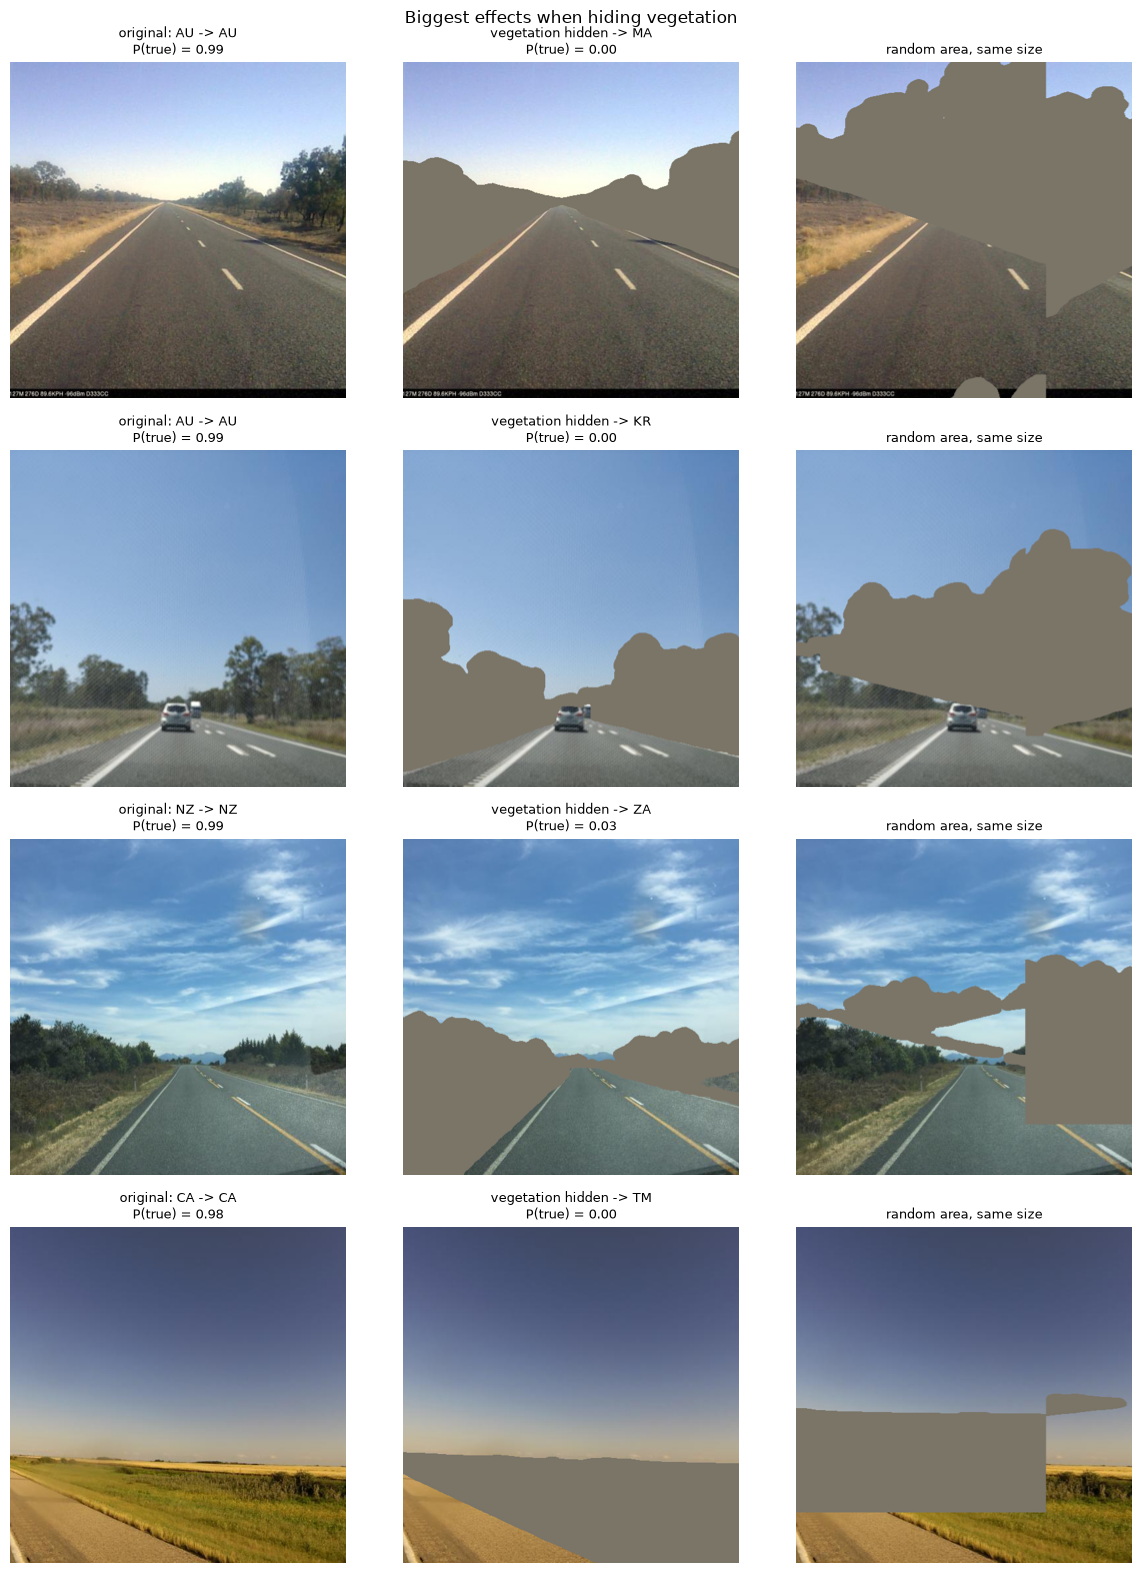

In [ ]:
DRILL_ELEMENT = summary.index[0]          # the strongest clue; change to look at others
N_SHOW = 4

top = pairs[pairs["element"] == DRILL_ELEMENT].sort_values("d_true_adj").head(N_SHOW)

fig, axes = plt.subplots(N_SHOW, 3, figsize=(12, 4 * N_SHOW))
for row, (_, r) in enumerate(top.iterrows()):
    img = dataset.get_image(r["id"])
    if DRILL_ELEMENT == "text":
        mask = text_detector.text_mask(img, image_id=r["id"])
    else:
        mask = segmenter.element_masks(img, image_id=r["id"])[DRILL_ELEMENT]
    result = applier.apply(img, mask, DRILL_ELEMENT)
    control = applier.apply_controls(img, result["mask"], n=1, seed=0)[0]

    axes[row, 0].imshow(fit_image(img, cfg.crop_mode))
    axes[row, 0].set_title(f"original: {r['country_id']} -> {r['orig_pred']}\n"
                           f"P(true) = {r['p_true_0']:.2f}", fontsize=9)
    axes[row, 1].imshow(fit_image(result["image"], cfg.crop_mode))
    axes[row, 1].set_title(f"{DRILL_ELEMENT} hidden -> {r['new_pred']}\n"
                           f"P(true) = {r['p_true']:.2f}", fontsize=9)
    axes[row, 2].imshow(fit_image(control["image"], cfg.crop_mode))
    axes[row, 2].set_title("random area, same size", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")
plt.suptitle(f"Biggest effects when hiding {DRILL_ELEMENT}")
plt.tight_layout()
plt.show()

## Answer to Q3

**Which elements matter?** The landscape is the strongest clue: hiding vegetation/terrain lowers P(true country) by 8.1 pts more than hiding a random area of the same size, and turns 66 % of correct predictions wrong (random area: 39 %). Buildings come second (−6.3 pts), but they're only in 29 % of the images. Road, signs/poles, vehicles and text each have a smaller but clear effect (about −2.3 to −2.5 pts). The sky isn't a clue: hiding it hurts less than a random area of the same size (+1.8 pts), because the random copies of the sky mask land on the ground and cover the landscape.

**Does it differ between regions?** Yes. Vegetation matters most in Oceania (−13.1 pts) and Europe (−10.2), buildings in Europe (−10.0) and Asia (−6.8), text mostly in Europe and the Americas (about −4 to −5), and road most in Oceania (−5.0). In the drill-down, Australian, New Zealand and Canadian roads are recognised at 98–99 %, but without vegetation they become Morocco, South Korea, South Africa or Turkmenistan.

**Link to Q2:** Q2 showed that the biggest confident errors come from an ambiguous word in the prompt, not from the image. Q3 shows what the model does use from the image: mostly the landscape.

**Cross-check:** pair A found the same order with a larger sample and their own analysis (vegetation strongest, then buildings, sky below a random area).

**Limitations:** gray blocks are unnatural inputs; "vegetation" includes terrain, and the segmentation isn't perfect (e.g. dirt roads can be labelled as terrain); 20 images per country, so per-country results are noisy; text is in only 6 % of the images, so its effect is uncertain.